# LeafLens: full pipeline (Part 1 preprocessing + Part 2 model)
Runtime -> Change runtime type -> **T4 GPU** before running.

## 1. Environment

In [ ]:
!pip install -q kaggle scikit-learn matplotlib
import torch, torchvision
print(torch.__version__, torchvision.__version__, "| GPU:", torch.cuda.is_available())

2.14.1+cu130 0.29.1+cu130 | GPU: True


## 2. Download PlantVillage (needs kaggle.json from Kaggle → Settings → Create New Token)

In [ ]:
from google.colab import files
files.upload()  # select kaggle.json
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d abdallahalidev/plantvillage-dataset -p data --unzip -q

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0


## 3. Index images + class counts

In [ ]:
from pathlib import Path
from collections import Counter

EXTS = {".jpg", ".jpeg", ".png"}
root = next(p for p in Path("data").rglob("color") if p.is_dir())
classes = sorted(d.name for d in root.iterdir() if d.is_dir())
class_to_idx = {c: i for i, c in enumerate(classes)}

paths, labels = [], []
for c in classes:
    for f in sorted((root / c).iterdir()):
        if f.suffix.lower() in EXTS:
            paths.append(str(f)); labels.append(class_to_idx[c])

print(root, "|", len(classes), "classes |", len(paths), "images")
for c, n in sorted(Counter(classes[l] for l in labels).items(), key=lambda x: x[1]):
    print(f"{n:6d}  {c}")

data/plantvillage dataset/color | 38 classes | 54305 images
   152  Potato___healthy
   275  Apple___Cedar_apple_rust
   360  Peach___healthy
   371  Raspberry___healthy
   373  Tomato___Tomato_mosaic_virus
   423  Grape___healthy
   456  Strawberry___healthy
   513  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
   621  Apple___Black_rot
   630  Apple___Apple_scab
   854  Cherry_(including_sour)___healthy
   952  Tomato___Leaf_Mold
   985  Corn_(maize)___Northern_Leaf_Blight
   997  Pepper,_bell___Bacterial_spot
  1000  Potato___Early_blight
  1000  Potato___Late_blight
  1000  Tomato___Early_blight
  1052  Cherry_(including_sour)___Powdery_mildew
  1076  Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
  1109  Strawberry___Leaf_scorch
  1162  Corn_(maize)___healthy
  1180  Grape___Black_rot
  1192  Corn_(maize)___Common_rust_
  1383  Grape___Esca_(Black_Measles)
  1404  Tomato___Target_Spot
  1478  Pepper,_bell___healthy
  1502  Blueberry___healthy
  1591  Tomato___healthy
  1645  Appl

## 4. Stratified 70/15/15 split (done BEFORE augmentation, so no leakage)

In [ ]:
import json, os
from sklearn.model_selection import train_test_split

SEED = 42
tr_p, tmp_p, tr_y, tmp_y = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
va_p, te_p, va_y, te_y = train_test_split(tmp_p, tmp_y, test_size=0.50, stratify=tmp_y, random_state=SEED)
print("train/val/test:", len(tr_p), len(va_p), len(te_p))

os.makedirs("leaflens", exist_ok=True)
json.dump({"classes": classes, "train": [tr_p, tr_y], "val": [va_p, va_y], "test": [te_p, te_y]},
          open("leaflens/splits.json", "w"))

train/val/test: 38013 8146 8146


## 5. Transforms, Dataset, DataLoaders

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet stats (needed for pretrained ResNet-50)

train_tf = T.Compose([
    T.RandomResizedCrop(224, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(20),
    T.ColorJitter(0.2, 0.2, 0.2),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(), T.Normalize(MEAN, STD)])

class LeafDS(Dataset):
    def __init__(self, paths, labels, tf):
        self.paths, self.labels, self.tf = paths, labels, tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

BS = 64
train_dl = DataLoader(LeafDS(tr_p, tr_y, train_tf), BS, shuffle=True, num_workers=2, pin_memory=True)
val_dl = DataLoader(LeafDS(va_p, va_y, eval_tf), BS, num_workers=2, pin_memory=True)
test_dl = DataLoader(LeafDS(te_p, te_y, eval_tf), BS, num_workers=2, pin_memory=True)

## 6. Class weights (used in the loss in the training step)

In [ ]:
import numpy as np

cnt = np.bincount(tr_y, minlength=len(classes))
class_weights = torch.tensor(cnt.sum() / (len(classes) * cnt), dtype=torch.float)
print("class weight range: %.2f - %.2f" % (class_weights.min().item(), class_weights.max().item()))

class weight range: 0.26 - 9.44


## 7. Sanity checks

batch: (64, 3, 224, 224) (64,) | mean -0.25 std 0.96


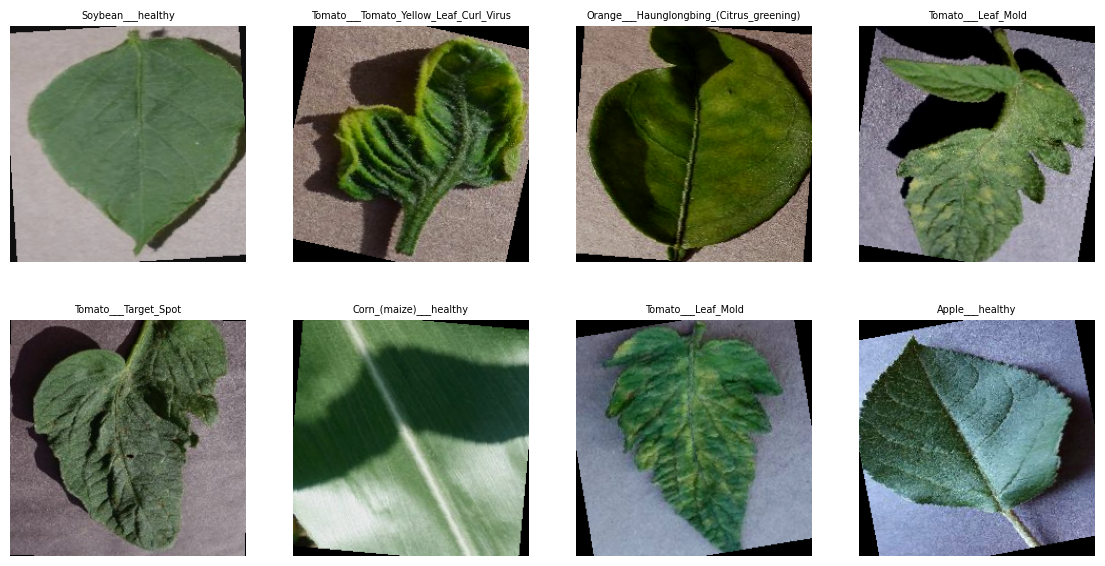

In [ ]:
import matplotlib.pyplot as plt

assert not ((set(tr_p) & set(va_p)) | (set(tr_p) & set(te_p)) | (set(va_p) & set(te_p))), "split leakage!"
assert all(len(set(y)) == len(classes) for y in (tr_y, va_y, te_y)), "class missing from a split"

x, y = next(iter(train_dl))
print("batch:", tuple(x.shape), tuple(y.shape), "| mean %.2f std %.2f" % (x.mean().item(), x.std().item()))

def show(x, y, n=8):
    x = (x[:n] * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1)
    fig, ax = plt.subplots(2, n // 2, figsize=(14, 7))
    for a, im, l in zip(ax.flat, x, y[:n]):
        a.imshow(im.permute(1, 2, 0)); a.set_title(classes[l], fontsize=7); a.axis("off")
    plt.show()

show(x, y)

# Part 2: ResNet-50 transfer learning, training, evaluation
Cells above (Part 1) are repeated so this notebook runs standalone. If your Part 1 runtime is still alive, skip straight to here.

## 8. Model: pretrained ResNet-50, new 38-class head

In [ ]:
import torch.nn as nn
from torchvision import models

device = "cuda"
assert torch.cuda.is_available(), "Switch runtime to GPU"

model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
model.fc = nn.Linear(model.fc.in_features, len(classes))  # 2048 -> 38
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
scaler = torch.amp.GradScaler("cuda")

def set_trainable(modules):
    for p in model.parameters():
        p.requires_grad = False
    for m in modules:
        for p in m.parameters():
            p.requires_grad = True
    print("trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 61.6MB/s]


## 9. Training utilities (BatchNorm kept in eval mode to preserve ImageNet statistics)

In [ ]:
import time, copy

def set_mode(train):
    model.train(train)
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.eval()

def run_epoch(loader, opt=None):
    train = opt is not None
    set_mode(train)
    total_loss = correct = n = 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                out = model(x)
                loss = criterion(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_acc = 0.0

def fit(epochs, lr, tag):
    global best_acc
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    for ep in range(epochs):
        t0 = time.time()
        tl, ta = run_epoch(train_dl, opt)
        vl, va = run_epoch(val_dl)
        sched.step()
        for k, v in zip(history, (tl, vl, ta, va)):
            history[k].append(v)
        if va > best_acc:
            best_acc = va
            torch.save(model.state_dict(), "leaflens/best.pt")
        print(f"[{tag}] epoch {ep+1}/{epochs} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f} | {time.time()-t0:.0f}s")

## 10. Phase 1: train only the new classifier head

In [ ]:
set_trainable([model.fc])
fit(epochs=2, lr=1e-3, tag="head")

trainable params: 77862
[head] epoch 1/2 | train loss 1.0361 acc 0.8431 | val loss 0.5867 acc 0.8944 | 224s
[head] epoch 2/2 | train loss 0.3820 acc 0.9272 | val loss 0.4642 acc 0.9127 | 224s


## 11. Phase 2: also fine-tune the last ResNet block (layer4) at a lower learning rate

In [ ]:
set_trainable([model.layer4, model.fc])
fit(epochs=3, lr=1e-4, tag="layer4")
print("best val acc:", best_acc)

trainable params: 15042598
[layer4] epoch 1/3 | train loss 0.1249 acc 0.9600 | val loss 0.1337 acc 0.9551 | 218s


## 12. Learning curves

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val"); ax[0].set_title("Loss")
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="val"); ax[1].set_title("Accuracy")
for a in ax:
    a.set_xlabel("epoch"); a.legend()
plt.show()

## 13. Test-set evaluation (best checkpoint by validation accuracy)

In [ ]:
from sklearn.metrics import classification_report, f1_score, confusion_matrix
import numpy as np

model.load_state_dict(torch.load("leaflens/best.pt"))
set_mode(False)
preds, ys = [], []
with torch.no_grad():
    for x, y in test_dl:
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            preds.append(model(x.to(device)).argmax(1).cpu())
        ys.append(y)
preds, ys = torch.cat(preds).numpy(), torch.cat(ys).numpy()

print("test accuracy: %.4f | macro-F1: %.4f" % ((preds == ys).mean(), f1_score(ys, preds, average="macro")))
print(classification_report(ys, preds, target_names=classes, digits=3))

## 14. Confusion matrix and most common mistakes

In [ ]:
cm = confusion_matrix(ys, preds)
plt.figure(figsize=(10, 9))
plt.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues")
plt.xlabel("predicted"); plt.ylabel("true"); plt.colorbar(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
for idx in np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]:
    t, p = idx
    print(f"{off[t, p]:3d} x  {classes[t]}  ->  {classes[p]}")

## 15. Real-world check: upload your own leaf photos (phone pictures, natural backgrounds)

In [ ]:
!git clone -q --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset
!ls PlantDoc-Dataset
!ls PlantDoc-Dataset/train | head -40